# Import required Data

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np

delays = gpd.read_file("data/ttc_bus_delays_combined.geojson")
thiessen_polygons = gpd.read_file("data/thiessen_polygons.geojson").set_index("gauge")[["geometry"]].set_crs(epsg=4326)

Get precipitation data throughout the years.

In [3]:
import requests
import os

if (os.path.exists("data/daily_precipitation.csv")):
    daily_precipitation = pd.read_csv("data/daily_precipitation.csv")
else:
    precipitation_data_frames = {}  


    base_url = "https://ckan0.cf.opendata.inter.prod-toronto.ca"
    url = base_url + "/api/3/action/package_show"
    params = {"id": "rain-gauge-locations-and-precipitation"}
    package = requests.get(url, params=params).json()

    for idx, resource in enumerate(package["result"]["resources"]):

        if not resource["datastore_active"]:
            url = base_url + "/api/3/action/resource_show?id=" + resource["id"]
            resource_metadata = requests.get(url).json()
            # print(resource_metadata)

            url = resource_metadata["result"]["url"]
            name = resource_metadata["result"]["name"].replace(
                ".csv", "").replace(".xlsx", "")

            # From here, you can use the "url" attribute to download this file
            # This only donwloads the .csv and.xlsx files and makes sure not to download multiple copies of the same package.
            if url.endswith(".csv"):
                precipitation_data_frames[name] = pd.read_csv(url)
   

In [4]:
# Get precipitation data from 2015 to 2026 and merge data frames into one data frame. This will be used to analyze the relationship between bus delays and precipitation.
# Collect all yearly dataframes first
if not os.path.exists("data/daily_precipitation.csv"):
    frames = [
        df
        for year in range(2015, 2027)
        if (df := precipitation_data_frames.get(f"precipitation-data-{year}")) is not None
    ]

    # Single concat
    precipitation = pd.concat(frames, ignore_index=True)

    # Convert rainfall once
    precipitation["rainfall"] = pd.to_numeric(
        precipitation["rainfall"],
        errors="coerce"
    )

    # Remove invalid rows
    precipitation = precipitation.dropna(
        subset=["date", "name", "longitude", "latitude", "rainfall"]
    )

    # Remove negative rainfall
    precipitation = precipitation.loc[
        precipitation["rainfall"] >= 0
    ]

    precipitation = (
        precipitation
        .drop_duplicates()
        .drop_duplicates(subset=["date", "name"], keep="first")
    )


    # Creating a dataframe of unique rain gauges. Drop duplicates to get unique gauges, sort by name in ascending order, and set the index as the name.
    gauges = (
        precipitation
        .drop_duplicates("name")
        [["name", "longitude", "latitude"]]
        .sort_values("name")
        .reset_index(drop=True)
    )

    # Only guages on from Nov 1st to Mar 31st
    year_round_gauges = {
        "RG_016",
        "RG_017",
        "RG_018",
        "RG_019",
        "RG_038",
    }

    four_season_gauges = gauges[
        gauges["name"].isin(year_round_gauges)
    ].reset_index(drop=True)

 # winter_precipitation = precipitation[(precipitation["Date"].str.split("-").str[1].astype(int) < 4) | ( precipitation["Date"].str.split("-").str[1].astype(int) > 10)]

# SciKit Learn Intergration

For generating the data, used the exisiting dely dates and appended some dates that didn't have delays for modeling that no delay day behiour. Some of the ttc data also have no delay instances that are also marked down. For example O'CONNER. 
- We need to decide how much data to append with no delay days
- How to treat no delay recods in TTC data
- How to treat missing rain gauges in data (currently treated with filling in as 0 for that day)
- How we parse out incorrect raingauge evaulations

## Daily Model

### Train/Test Split and Seasonal Split

In [5]:

# Aggregate rainfall by day and gauge or import daily precipitation data from csv if it exists
if not os.path.exists("data/daily_precipitation.csv"):
    # Ensure dates use a consistent datetime type and remove time components
    precipitation["day"] = precipitation["date"].str[:10]
    # Sums precipitation by day and gauge, and saves the result to a CSV file for future use
    daily_precipitation = (
        precipitation.groupby(["day", "name"], as_index=False)["rainfall"]
        .sum()
    )
    daily_precipitation.to_csv("data/daily_precipitation.csv", index=False)

# remoce time stamp for dates
daily_precipitation["day"] = pd.to_datetime(daily_precipitation["day"]).dt.normalize()

delays["Date"] = delays["Date"].dt.normalize()

# sum delays at station level for each day
all_delays = (
    delays[["Date", "Station", "geometry","Min Delay"]]
    .groupby(["Station", "Date"], as_index=False)
    .agg({ "geometry": "first", "Min Delay": "sum"})
)

# Delays start earlier than the precipitation data, so filter delays to only include dates that are present in the daily precipitation data.
delays = all_delays[all_delays["Date"].isin(daily_precipitation["day"])]

stations = (
    delays[["Station", "geometry"]]
    .dropna()
    .drop_duplicates(subset=["Station"])
)
stations = stations.set_geometry("geometry")

Create list of possible target dates. ANd split them into winter and summer.

Editable:
- Number of non-delay dates selected

In [25]:
# Get unique dates with delays and add in dates not in delays to set
delay_dates = delays["Date"].unique()

# Ensure both collections are DatetimeIndex objects before using difference()
precipitation_dates = daily_precipitation["day"].unique()
# Get days where no delays occured
no_delay_dates = list(set(precipitation_dates) - set(delay_dates))

# Randomly select addition of remaining dates. Approximately for every 13 days with no delays there is a delay date.
np.random.seed(0)
selected_no_delay_dates = np.random.choice(no_delay_dates, size=int(len(delay_dates) * 5), replace=False)


all_dates = (
    pd.DatetimeIndex(delay_dates)
    .append(pd.DatetimeIndex(selected_no_delay_dates))
    .drop_duplicates()
)

winter_dates = all_dates[all_dates.month.isin([11, 12, 1, 2, 3])]
summer_dates = all_dates[all_dates.month.isin([4, 5, 6, 7, 8, 9, 10])]


Split the dates into train and test

In [26]:
from sklearn.model_selection import train_test_split

winter_train_dates, winter_test_dates = train_test_split(winter_dates, test_size=0.2, random_state=0,shuffle=True)
summer_train_dates, summer_test_dates = train_test_split(summer_dates, test_size=0.2, random_state=0,shuffle=True)

# There is a discrepency in guages provided from day to day, where guage values are not provided, set them to 0.
all_gauges = thiessen_polygons.index.unique().tolist()
all_stations = stations["Station"].unique().tolist()

### Feature Selection and Preprocessing

Features to be implemented:
- IDW rain at the station locations (1 entry per station)
- Amount of precipitation in overall area (1 entry for per day)
- Amount of precipitation at station in the past 24 hours (1 entry per station)
- Amount of precipitation in overall area in 24 hours (1 entry for day)
- Number of weather related delays in past week (1 entry per station)

In [8]:
thiessen_centroids = thiessen_polygons.geometry.centroid
# Use the GeoSeries directly to avoid the active-geometry error
stations_distances = thiessen_centroids.apply(
    lambda centroid: stations.geometry.distance(centroid)
).rename(columns=stations["Station"])

C:\Users\nikit\AppData\Local\Temp\ipykernel_26796\1607184377.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  thiessen_centroids = thiessen_polygons.geometry.centroid


In [27]:


def create_station_day_features(stations_distances, guages, delays, precipitation, no_precipitation_dates):
    """Create features for each station and day"""

    # Base frame of real delays
    X = delays[["Date", "Station", "Min Delay"]].copy()

    # Total rainfall for each day
    daily_rainfall_total = precipitation.groupby("day")["rainfall"].sum()

    # Index = date, columns = gauge; missing values filled with 0
    daily_precipitation_by_gauge = (
        precipitation.pivot_table(
            index="day", columns="name", values="rainfall")
        .reindex(index=precipitation["day"].unique(), columns=guages)
        .fillna(0)
    )

    # IDW for each day and station (days x stations)
    idw = daily_precipitation_by_gauge.dot(stations_distances)

    # Synthetic zero-delay rows for dry days
    no_delays = pd.DataFrame({
        "Date": pd.to_datetime(no_precipitation_dates),
        "Station": np.random.choice(X["Station"].unique(), size=len(no_precipitation_dates)),
    })
    no_delays["Min Delay"] = 0

    # Force identical datetime resolution, no timezone
    x_dates = pd.to_datetime(X["Date"]).dt.tz_localize(
        None).astype("datetime64[ns]")
    nd_dates = pd.to_datetime(no_delays["Date"]).dt.tz_localize(
        None).astype("datetime64[ns]")

    X = pd.DataFrame({
        "Date": np.concatenate([x_dates.to_numpy(), nd_dates.to_numpy()]),
        "Station": np.concatenate([X["Station"].to_numpy(), no_delays["Station"].to_numpy()]),
        "Min Delay": np.concatenate([X["Min Delay"].to_numpy(), no_delays["Min Delay"].to_numpy()]),
    })

    # ---- Helper lookups that return 0 when a date/station is missing ----
    idw_long = idw.stack()  # MultiIndex (day, station)

    def idw_lookup(dates, stations):
        idx = pd.MultiIndex.from_arrays([dates, stations])
        return idw_long.reindex(idx).fillna(0).to_numpy()

    def rainfall_lookup(dates):
        return daily_rainfall_total.reindex(dates).fillna(0).to_numpy()

    one_day = pd.Timedelta(days=1)
    yesterday = X["Date"] - one_day

    # ---- Rainfall features ----
    X["IDW"] = np.log1p(idw_lookup(X["Date"], X["Station"]))
    X["IDW yesterday"] = np.log1p(idw_lookup(yesterday, X["Station"]))
    X["total_rainfall"] = np.log1p(rainfall_lookup(X["Date"]))
    X["yesterday_rainfall"] = np.log1p(rainfall_lookup(yesterday))
    X["encoded_station"] = X["Station"].astype("category").cat.codes

    # ---- Past-week delay per station (excludes current day, so no target leakage) ----
    
    past_week = (
        X.set_index("Date").sort_index()
        .groupby("Station")["Min Delay"]
        .rolling("7D", closed="left")   # window [Date - 7 days, Date)
        .sum()
        .rename("delay_past_week")
        .reset_index()
    )
    X = X.merge(past_week, on=["Station", "Date"], how="left")
    X["delay_past_week"] = np.log1p(X["delay_past_week"].fillna(0))

    # ---- Target transform (must stay AFTER the past-week calculation) ----
    X["Min Delay"] = np.log1p(X["Min Delay"])
    print(len(X), len(no_delays), len(delays))

    return X

In [28]:
X_all = create_station_day_features(
    stations_distances,
    all_gauges,
    delays,
    daily_precipitation,
    selected_no_delay_dates
)
display(X_all)

3312 1430 1882


,Date,Station,Min Delay,IDW,IDW yesterday,total_rainfall,yesterday_rainfall,encoded_station,delay_past_week
0,2026-01-27,1 O'CONNOR DR,0.000000,1.307730,1.772319,3.404359,4.040240,0,0.0
1,2026-02-18,105 IRONSIDE CRES,0.000000,5.154245,0.324937,6.715307,1.501184,1,0.0
2,2026-02-10,1060 MIDLAND AVE,2.772589,3.208756,0.415148,4.991317,1.774444,2,0.0
3,2025-12-10,1120 KEELE ST,2.397895,4.352043,3.690089,6.396558,5.519719,3,0.0
4,2026-02-18,1132 PROGRESS AVE,2.772589,5.113214,0.307483,6.715307,1.501184,4,0.0
...,...,...,...,...,...,...,...,...,...
3307,2024-10-06,SCARLETT AND EGLINTON,0.000000,2.662920,0.210969,3.932061,0.747162,846,0.0
3308,2016-03-12,HUMBERWOOD AND MORNING,0.000000,0.000000,0.000000,0.000000,0.000000,489,0.0
3309,2024-03-11,MCNICOLL AND MIDLAND,0.000000,0.077981,1.141962,0.683097,2.463853,699,0.0
3310,2023-04-08,DON MILLS AND WYNFORD,0.000000,0.291832,0.051950,1.216988,0.337900,255,0.0


Check Collinearity and Correlation

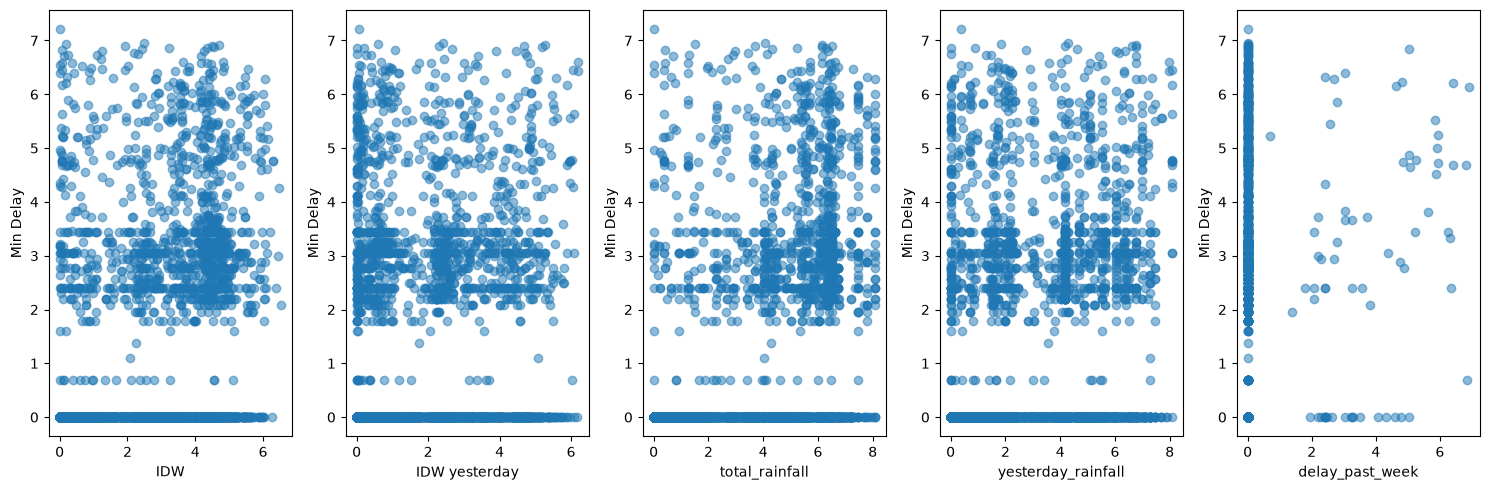

In [37]:
# Plot all features for a single station to visualize the relationships between features and target variable
fig, axes = plt.subplots(1, 5, figsize=(15, 5))
axes = axes.ravel()

for idx, feature in enumerate(["IDW", "IDW yesterday", "total_rainfall", "yesterday_rainfall", "delay_past_week"]):
    axes[idx].scatter(X_all[feature], X_all["Min Delay"], alpha=0.5)
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel("Min Delay")


plt.tight_layout()
plt.show()

### Train Test Split

In [29]:
from sklearn.model_selection import train_test_split

X_winter = X_all[X_all["Date"].isin(winter_dates)][["IDW", "IDW yesterday", "total_rainfall", "yesterday_rainfall", "encoded_station", "delay_past_week"]]
Y_winter = X_all[X_all["Date"].isin(winter_dates)]["Min Delay"]

X_winter_train, X_winter_test, Y_winter_train, Y_winter_test = train_test_split(X_winter, Y_winter, test_size=0.2, random_state=0, shuffle=True)

X_summer = X_all[X_all["Date"].isin(summer_dates)][[
    "IDW", "IDW yesterday", "total_rainfall", "yesterday_rainfall", "encoded_station", "delay_past_week"]]
Y_summer = X_all[X_all["Date"].isin(summer_dates)]["Min Delay"]

X_summer_train, X_summer_test, Y_summer_train, Y_summer_test = train_test_split(X_summer, Y_summer, test_size=0.2, random_state=0, shuffle=True)

### Implement Hurdle Model

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.linear_model import LogisticRegression
# Predicts only postive values, which is what we want for delays. It also has a log link function, which is what we want for our data.
from sklearn.linear_model import GammaRegressor

classifier = LogisticRegression(max_iter=1000)
regressor = GammaRegressor(max_iter=1000, alpha=0.1)

classifier.fit(X_winter_train, (Y_winter_train > 0).astype(int))

prob_delays = classifier.predict_proba(X_winter_train)[:, 1]

regressor.fit(X_winter_train[Y_winter_train > 0], Y_winter_train[Y_winter_train > 0])

delay_magnitude = regressor.predict(X_winter_train)


#### Classifier Model Confusion Matrix

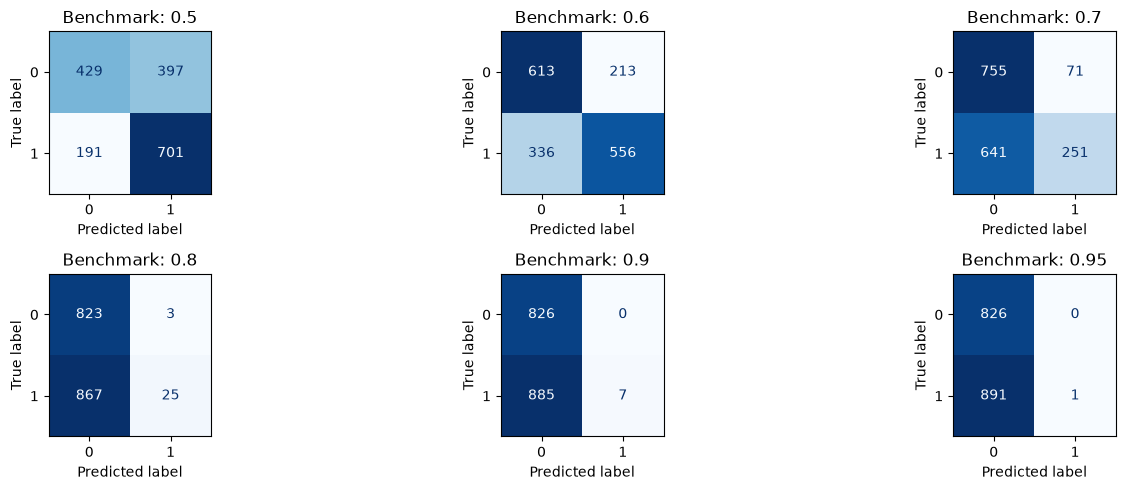

In [44]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# display confusion matrix for winter train data
benchmarks = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

fig, axes = plt.subplots(2, 3, figsize=(15, 5))
axes = axes.ravel()

for idx, benchmark in enumerate(benchmarks):
    cm = confusion_matrix(
        (Y_winter_train > 0).astype(int),
        (prob_delays > benchmark).astype(int)
    )

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[idx], cmap=plt.cm.Blues, colorbar=False)
    axes[idx].set_title(f"Benchmark: {benchmark}")


plt.tight_layout()
plt.show()


Testing random forest classifier on TRAINING

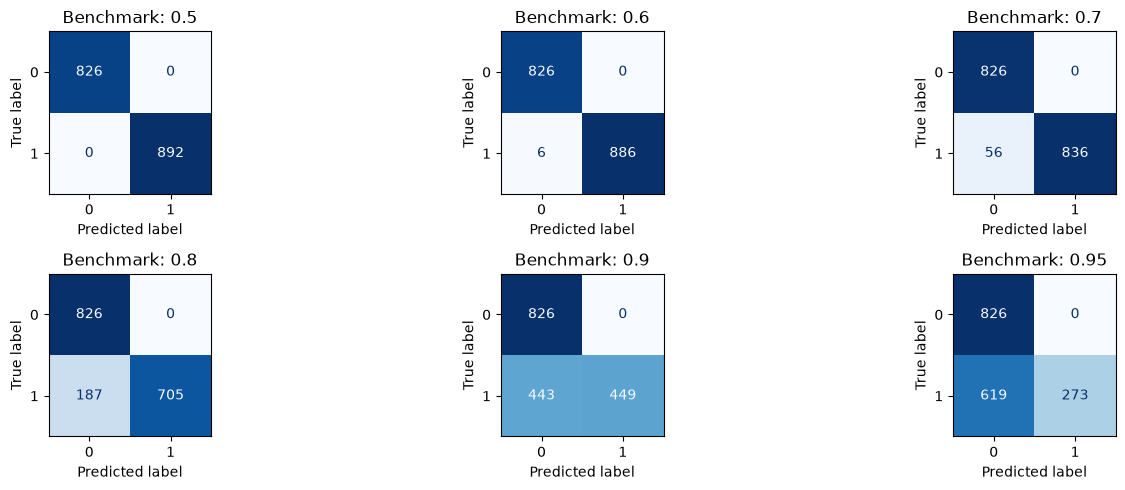

Winter Train Data:


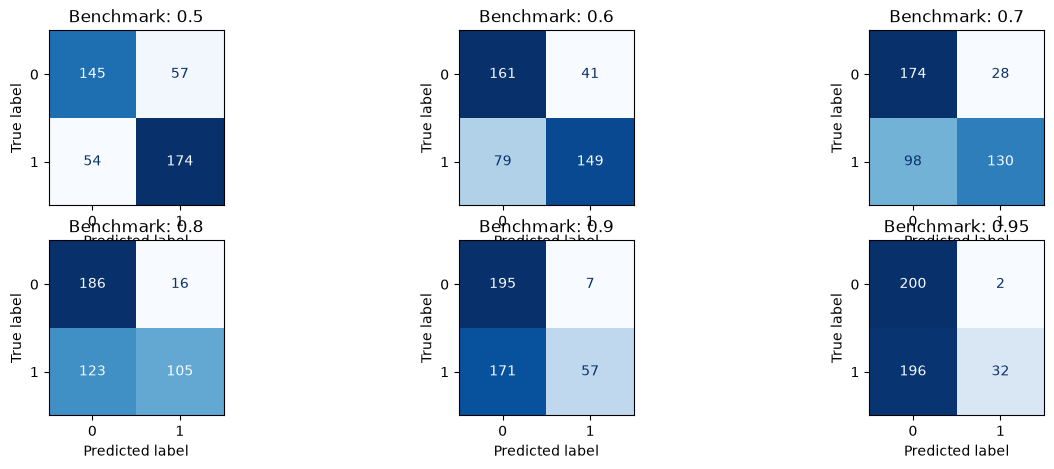

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
# Predicts only postive values, which is what we want for delays. It also has a log link function, which is what we want for our data.
from sklearn.linear_model import GammaRegressor

forest_classifier = RandomForestClassifier(n_estimators=100, random_state=0, class_weight="balanced")

forest_classifier.fit(X_winter_train, (Y_winter_train > 0).astype(int))

forest_prob_delays = forest_classifier.predict_proba(X_winter_train)[:, 1]


# display confusion matrix for winter train data
benchmarks = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

fig, axes = plt.subplots(2, 3, figsize=(15, 5))
axes = axes.ravel()

for idx, benchmark in enumerate(benchmarks):
    cm = confusion_matrix(
        (Y_winter_train > 0).astype(int),
        (forest_prob_delays > benchmark).astype(int)
    )

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[idx], cmap=plt.cm.Blues, colorbar=False)
    axes[idx].set_title(f"Benchmark: {benchmark}")


plt.tight_layout()
plt.show()

print("Winter Test Data:")

fig, axes = plt.subplots(2, 3, figsize=(15, 5))
axes = axes.ravel()

for idx, benchmark in enumerate(benchmarks):
    cm = confusion_matrix(
        (Y_winter_test > 0).astype(int),
        (forest_classifier.predict_proba(X_winter_test)[:, 1] > benchmark).astype(int)
    )

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[idx], cmap=plt.cm.Blues, colorbar=False)
    axes[idx].set_title(f"Benchmark: {benchmark}")

plt.title(f"Benchmark: {benchmark}")
plt.show()

In [84]:
forest_pred_delays = np.where(forest_prob_delays < 0.5, 0, forest_prob_delays * np.expm1(delay_magnitude))
pred_delays = np.where(prob_delays < 0.5, 0, prob_delays * np.expm1(delay_magnitude))

In [ ]:
comparison = pd.DataFrame({
    "Actual": Y_winter_train,
    "Probability of Delay": prob_delays,
    "Forest Probability": forest_prob_delays,
    "Predicted": pred_delays,
    "Forest Predicted": forest_pred_delays
}, index=Y_winter_train.index)

comparison

,Actual,Probability of Delay,Forest Probability,Predicted,Forest Predicted
519,0.000000,0.589039,0.22,16.085924,0.000000
797,4.691348,0.612971,0.90,17.774694,26.097849
516,6.580639,0.158077,0.86,0.000000,24.803463
1247,0.000000,0.602604,0.21,17.737152,0.000000
2700,0.000000,0.173010,0.00,0.000000,0.000000
...,...,...,...,...,...
1209,2.484907,0.553559,0.79,15.503780,22.125906
2218,0.000000,0.556618,0.10,16.158106,0.000000
904,0.000000,0.517741,0.09,15.077644,0.000000
988,3.218876,0.593859,0.80,18.230364,24.558499


: 